<a href="https://colab.research.google.com/github/KacChw/Machine-Learning-Labolatory-Master-Course-Big-Data/blob/main/ML_Cw02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# podstawode zagodnienia z szeregow czasowych, bez sieci neuronowych
# zbior 'flights' szereg czasowy, miesieczna licxba pasazerow, wersja odporna na 'locale, przy konwersji nazw miesiecy

!pip -q install seaborn

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

flights = sns.load_dataset("flights")
flights.head(10)

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
5,1949,Jun,135
6,1949,Jul,148
7,1949,Aug,148
8,1949,Sep,136
9,1949,Oct,119


In [ ]:
# Konwersja odporna na locale: pełna nazwa miesiąca (%B), potem skrót (%b)
month_num = pd.to_datetime(
    flights["month"].astype(str),
    format="%B",
    errors="coerce"
).dt.month

mask_na = month_num.isna()

if mask_na.any():
    month_num.loc[mask_na] = pd.to_datetime(
        flights.loc[mask_na, "month"].astype(str),
        format="%b",
        errors="coerce"
    ).dt.month

if month_num.isna().any():
    raise ValueError("Blad wczytywania wszystkich msc")

flights["date"] = pd.to_datetime({
    "year": flights["year"].astype(int),
    "month": month_num.astype(int),
    "day": 1
})

flights_ts = flights.set_index("date").sort_index()
flights_ts = flights_ts[["passengers"]].asfreq("MS")

print("\nFLIGHTS (po konwersji, indeks DatetimeIndex):")
print(flights_ts.head(10))


FLIGHTS (po konwersji, indeks DatetimeIndex):
            passengers
date                  
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
1949-06-01         135
1949-07-01         148
1949-08-01         148
1949-09-01         136
1949-10-01         119


/tmp/ipykernel_444/1149352486.py:11: SettingWithCopyWarning: modifications to a property of a datetimelike object are not supported and are discarded. Change values on the original.
  month_num.loc[mask_na] = pd.to_datetime(



Suma pasazerow na rok:
date
1949-12-31    1520
1950-12-31    1676
1951-12-31    2042
1952-12-31    2364
1953-12-31    2700
1954-12-31    2867
1955-12-31    3408
1956-12-31    3939
1957-12-31    4421
1958-12-31    4572
1959-12-31    5140
1960-12-31    5714
Freq: YE-DEC, Name: passengers, dtype: int64

Srednia ruchoma 12 miesiecy:
            passengers       MA_12  YoY_%
date                                     
1949-01-01         112  112.000000    NaN
1949-02-01         118  115.000000    NaN
1949-03-01         132  120.666667    NaN
1949-04-01         129  122.750000    NaN
1949-05-01         121  122.400000    NaN

Zmiana YoY:
            passengers       MA_12  YoY_%
date                                     
1949-01-01         112  112.000000    NaN
1949-02-01         118  115.000000    NaN
1949-03-01         132  120.666667    NaN
1949-04-01         129  122.750000    NaN
1949-05-01         121  122.400000    NaN


/tmp/ipykernel_444/1397494240.py:3: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  annual_sum = flights_ts.resample("A")["passengers"].sum()


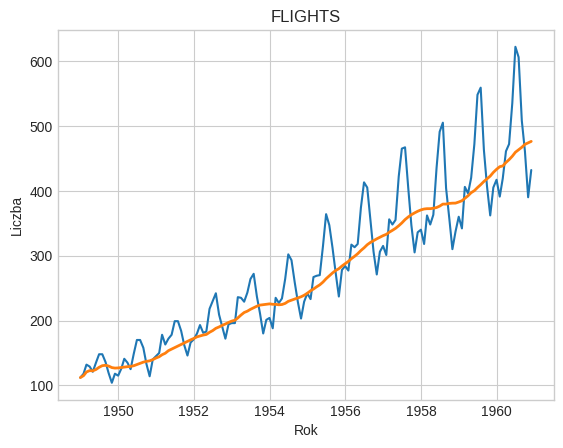

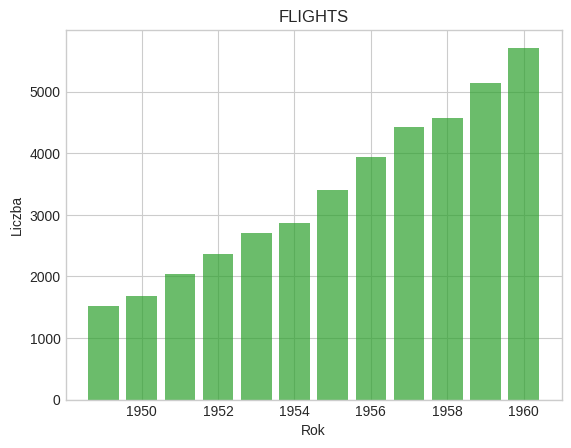

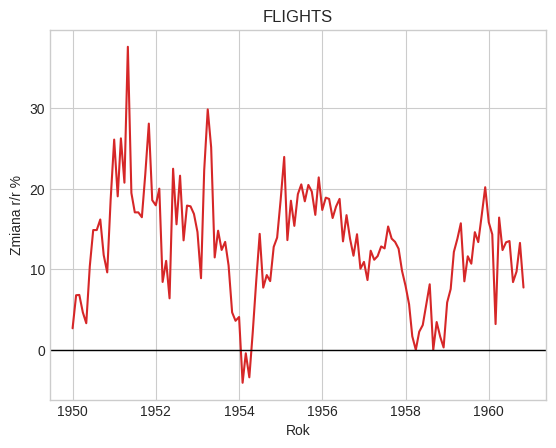

In [ ]:
# podstawowe operacje na szeregach

annual_sum = flights_ts.resample("A")["passengers"].sum()

print("\nSuma pasazerow na rok:")
print(annual_sum)

# srednia ruchoma 12-msc wyladzanie sezonowosci

flights_ts = flights_ts.copy()
flights_ts["MA_12"] = flights_ts["passengers"].rolling(window=12, min_periods=1).mean()

print("\nSrednia ruchoma 12 miesiecy:")
print(flights_ts.head(5))

# dynamika r/r zmiany rok do roku
flights_ts["YoY_%"] = flights_ts["passengers"].pct_change(periods=12)*100
print("\nZmiana YoY:")
print(flights_ts.head(5))

#wykresy szeregu matplotlib

plt.figure()
plt.plot(flights_ts.index, flights_ts["passengers"], label="Pasazerowie miesiecznie", color="tab:blue")
plt.plot(flights_ts.index, flights_ts["MA_12"], label="Srednia ruchoma 12 miesiecy", color="tab:orange", linewidth=2)
plt.title("FLIGHTS")
plt.xlabel("Rok")
plt.ylabel("Liczba")
plt.show()

# sumy roczne wykres slupkowy

plt.figure()
plt.bar(annual_sum.index.year, annual_sum.values, color="tab:green", alpha=0.7)
plt.title("FLIGHTS")
plt.xlabel("Rok")
plt.ylabel("Liczba")
plt.show()

#zmiany r/r yoy w p.p

plt.figure()
plt.plot(flights_ts.index[:-1], flights_ts["YoY_%"][:-1], color="tab:red")
plt.axhline(0, color="black", linewidth=1)
plt.title("FLIGHTS")
plt.xlabel("Rok")
plt.ylabel("Zmiana r/r %")
plt.show()

Liczba braków: 8


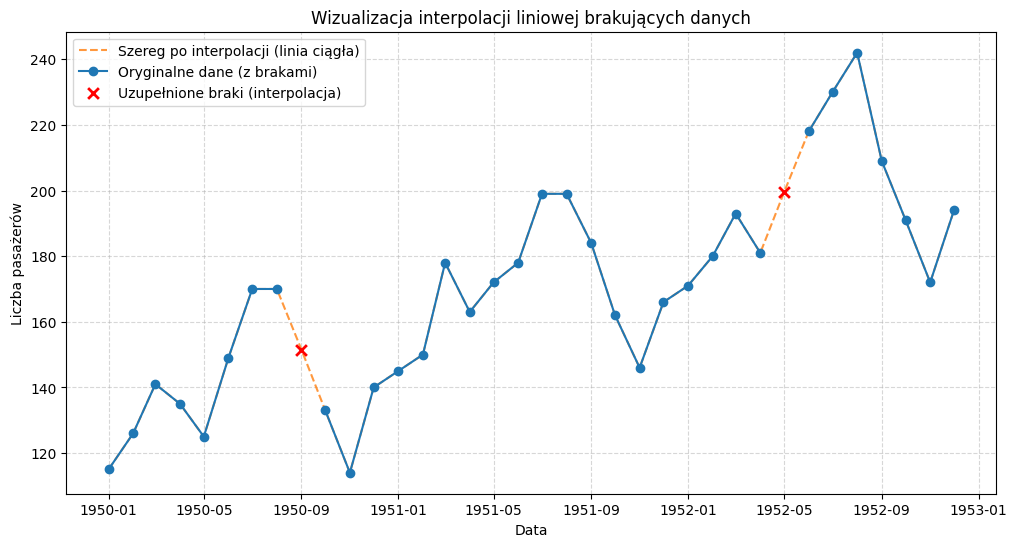

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Upewniamy się, że dane flights_ts są dostępne
if 'flights_ts' not in globals():
    flights = sns.load_dataset("flights").copy()
    month_num = pd.to_datetime(flights["month"].astype(str), format="%B", errors="coerce").dt.month
    mask_na = month_num.isna()
    if mask_na.any():
        # Poprawione przypisanie bez ostrzeżeń SettingWithCopyWarning
        fallback_months = pd.to_datetime(flights.loc[mask_na, "month"].astype(str), format="%b", errors="coerce").dt.month
        month_num = month_num.fillna(fallback_months)
    flights["date"] = pd.to_datetime({
        "year": flights["year"].astype(int),
        "month": month_num.astype(int),
        "day": 1
    })
    flights_ts = flights.set_index("date").sort_index()
    flights_ts = flights_ts[["passengers"]].asfreq("MS")

# Przykład braków i uzupełnień braków w szeregach
flights_na = flights_ts.copy()

# Tworzymy sztuczne braki danych (co 20 punktów)
missing_indices = flights_na.iloc[::20].index
flights_na.loc[missing_indices, "passengers"] = np.nan
print("Liczba braków:", flights_na["passengers"].isna().sum())

# Uzupełnienie danych liniową interpolacją
flights_na["passengers_lin"] = flights_na["passengers"].interpolate(method="linear")

# Wybór podzbioru danych do lepszej wizualizacji szczegółów
subset = flights_na.loc["1950":"1952"].copy()

# Wyznaczenie punktów, które były brakujące w wybranym podzbiorze
interpolated_points = subset[subset["passengers"].isna()]

plt.figure(figsize=(12, 6))

# Rysujemy linię interpolowaną w tle
plt.plot(subset.index, subset["passengers_lin"], label="Szereg po interpolacji (linia ciągła)", color="tab:orange", linestyle="--", alpha=0.8)

# Rysujemy oryginalne dane z jawnymi przerwami (brakami)
plt.plot(subset.index, subset["passengers"], label="Oryginalne dane (z brakami)", color="tab:blue", marker='o', markersize=6)

# Zaznaczamy dokładnie te punkty, które zostały wyinterpolowane
plt.scatter(interpolated_points.index, interpolated_points["passengers_lin"],
            color="red", zorder=5, s=60, label="Uzupełnione braki (interpolacja)", marker='x', linewidths=2)

plt.title("Wizualizacja interpolacji liniowej brakujących danych")
plt.xlabel("Data")
plt.ylabel("Liczba pasażerów")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()